# Big West Predictor | 2021


In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path('../data/processed')

In [2]:
results = pd.read_csv(DATA_DIR / 'bigwest_2021_2026_results.csv', dtype={'athlete_id': 'Int64'})
team_scores = pd.read_csv(DATA_DIR / 'bigwest_2021_2026_team_scores.csv')
roster = pd.read_csv(DATA_DIR / 'bigwest_roster.csv', dtype={'athlete_id': 'Int64'})
regular_season = pd.read_csv(DATA_DIR / 'regular_season.csv', dtype={'athlete_id': 'Int64'})
national_rank = pd.read_csv(DATA_DIR / 'national_event_ranking.csv')

results_2021 = results[results['meet_year'] == 2021]
results_2021.head()

,athlete_id,athlete_name,team,meet_name,meet_year,gender,event,mark,mark_unit,place,wind,event_type,points
3937,7657050,Benjamin Goodwin,UC Davis,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.67,seconds,1.0,NaN,track,10.0
3938,6110870,Chineme Allison,Cal Poly,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.68,seconds,2.0,NaN,track,8.0
3939,6597023,Rasaun House,Cal St. Fullerton,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.71,seconds,3.0,NaN,track,6.0
3940,7152233,Tyler Esteves,Cal Poly,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.71,seconds,4.0,NaN,track,5.0
3941,6163778,Kent Harris,Long Beach St.,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.77,seconds,5.0,NaN,track,4.0


## 2021: Predicting championship marks from regular-season marks

For each athlete's championship event, we build five features from their 2021 regular-season marks in that same event (outdoor meets before the championships on May 12, 2021 only; indoor marks aren't comparable, and 2021 had no indoor season anyway). Then we fit a one-feature linear regression for each feature and score it with R².

If an athlete has several marks at one meet (e.g. prelim + final), we keep their best mark from that meet.

| Feature | Definition |
|---|---|
| Season median | Median mark across the season's meets |
| Mean of last 3 meets | Average of the last 3 meets before the championships |
| Most recent meet | The last meet before the championships |
| Wind-legal season best | Best mark with wind ≤ +2.0 m/s. Only differs from season best in the 100, 200, hurdles, long jump and triple jump. Marks with no wind reading don't count as legal. |
| Season best | Best mark of the season |

**Target:** the athlete's championship mark from `results` (their final if they made it, otherwise their prelim). Relays and multi-events are excluded, as are DNF, FOUL, NH, etc. A championship mark more than 50% worse than the athlete's own season best is treated like a DNF too (e.g. injured and jogged in). In 2021 that's one race: a 1:40.56 in the men's 400m final from a runner who ran 48.28 in the prelims.

**Two R² scores** (both use the same athletes; they differ in *which differences* they try to explain):
- **Raw R²** fits one line across every event. It comes out near 1.0 for every feature because events are on different scales (a 10k takes ~30 minutes, a 100m ~11 seconds), so it doesn't tell the features apart.
- **Within-event R²** first converts each mark to "standard deviations from the event average" (same gender + event). It measures how well a feature predicts who does better *within* an event. **Use this one to compare features.**

In [3]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# First day of each Big West Championships; only regular-season marks before it count
CHAMPS_START = {2021: '2021-05-12', 2022: '2022-05-13'}
WIND_EVENTS = {'100', '200', '100H', '110H', 'LJ', 'TJ'}
WIND_LIMIT = 2.0  # m/s
MIN_ATHLETES_PER_EVENT = 5  # need a few athletes to standardize within an event
MAX_OFF_SEASON_BEST = 0.5  # championship marks >50% worse than the athlete's season best aren't a real race

# Championship event names -> regular-season event codes
EVENT_CODES = {
    '100 Meters': '100', '200 Meters': '200', '400 Meters': '400', '800 Meters': '800',
    '1500 Meters': '1500', '5000 Meters': '5000', '10,000 Meters': '10,000',
    '100 Hurdles': '100H', '110 Hurdles': '110H', '400 Hurdles': '400H',
    '3000 Steeplechase': '3000S',
    'High Jump': 'HJ', 'Pole Vault': 'PV', 'Long Jump': 'LJ', 'Triple Jump': 'TJ',
    'Shot Put': 'SP', 'Discus': 'DT', 'Hammer': 'HT', 'Javelin': 'JT',
}

FEATURES = {
    'median_mark': 'Season median',
    'last3_mean': 'Mean of last 3 meets',
    'most_recent': 'Most recent meet',
    'wind_legal_sb': 'Wind-legal season best',
    'season_best': 'Season best',
}

# Events held only indoors / only outdoors, used to tell indoor meets apart
INDOOR_ONLY_EVENTS = {'60', '60H', 'WT', 'Pent'}
OUTDOOR_ONLY_EVENTS = {'100', '100H', '110H', '400H', '3000S', '10,000', 'DT', 'HT', 'JT', '4x100', 'Dec'}


def to_number(mark):
    """'10.74' -> 10.74, '3:44.68' -> 224.68, '7.45m' -> 7.45, 'DNF'/'FOUL' -> NaN."""
    text = str(mark).strip().removesuffix('m')
    try:
        return sum(float(part) * 60**i for i, part in enumerate(reversed(text.split(':'))))
    except ValueError:
        return np.nan


# A meet is indoor if "Indoor" is in its name, or it has no outdoor-only events
# and either has indoor-only events or is in January/February.
meet_events = regular_season.groupby(['meet_name', 'meet_start_date'])['event']
has_outdoor_event = meet_events.transform(lambda e: e.isin(OUTDOOR_ONLY_EVENTS).any())
has_indoor_event = meet_events.transform(lambda e: e.isin(INDOOR_ONLY_EVENTS).any())
jan_or_feb = pd.to_datetime(regular_season['meet_start_date']).dt.month <= 2
regular_season['is_indoor'] = (regular_season['meet_name'].str.contains('indoor', case=False)
                               | (~has_outdoor_event & (has_indoor_event | jan_or_feb)))


def season_features(g):
    best = 'min' if g['lower_is_better'].iat[0] else 'max'
    # One mark per meet (the athlete's best there), in date order
    per_meet = g.groupby(['date', 'meet_name'])['mark_num'].agg(best).sort_index()
    legal = g.loc[g['wind_legal'], 'mark_num']
    return pd.Series({
        'n_meets': len(per_meet),
        'median_mark': per_meet.median(),
        'last3_mean': per_meet.tail(3).mean(),
        'most_recent': per_meet.iloc[-1],
        'wind_legal_sb': legal.agg(best) if len(legal) else np.nan,
        'season_best': per_meet.agg(best),
    })


def build_model_data(year):
    """One row per athlete-event at that year's championships, with regular-season features."""
    # Target: championship mark (individual track and field events)
    champs = results[(results['meet_year'] == year)
                     & results['event_type'].isin(['track', 'field'])].copy()
    champs['gender'] = champs['gender'].str.capitalize()
    champs['event_code'] = (champs['event']
                            .str.replace(r"^(?:Men|Women)'s ", '', regex=True)
                            .map(EVENT_CODES))
    assert champs['event_code'].notna().all(), 'Unmapped championship event'
    champs['final_mark'] = champs['mark'].map(to_number)
    champs = champs.dropna(subset=['athlete_id', 'final_mark'])  # drops DNF, FOUL, NH, ...

    # Outdoor regular-season marks from before the championships
    season = regular_season[(regular_season['year'] == year) & ~regular_season['is_indoor']].copy()
    season['date'] = pd.to_datetime(season['meet_start_date'])
    season = season[season['date'] < pd.Timestamp(CHAMPS_START[year])]
    season = season.rename(columns={'event': 'event_code'})
    season['mark_num'] = season['mark'].map(to_number)
    season = season.dropna(subset=['mark_num'])
    season['lower_is_better'] = season['event_type'].eq('track')
    season['wind_legal'] = ~season['event_code'].isin(WIND_EVENTS) | (season['wind'] <= WIND_LIMIT)

    keys = ['athlete_id', 'gender', 'event_code']
    features = season.groupby(keys).apply(season_features, include_groups=False).reset_index()

    # Keep athletes with every feature, so all five models use the same rows
    data = champs.merge(features, on=keys, how='inner').dropna(subset=list(FEATURES))

    # Treat marks far off the athlete's own season best like a DNF (e.g. injured and jogged in)
    off_best = np.where(data['event_type'] == 'track',
                        data['final_mark'] / data['season_best'] - 1,
                        1 - data['final_mark'] / data['season_best'])
    not_a_race = off_best > MAX_OFF_SEASON_BEST
    if not_a_race.any():
        print(f'{year}: dropped as not a real race:')
        print(data.loc[not_a_race, ['event', 'athlete_name', 'final_mark', 'season_best']].to_string(index=False))
    data = data[~not_a_race]

    event_size = data.groupby('event')['athlete_id'].transform('size')
    data = data[event_size >= MIN_ATHLETES_PER_EVENT].copy()
    print(f'{year}: {len(champs)} championship marks -> {len(data)} with regular-season '
          f'marks in the same event {data["event_type"].value_counts().to_dict()}')
    return data


model_data = build_model_data(2021)
model_data[['athlete_name', 'gender', 'event_code', 'final_mark', 'n_meets', *FEATURES]].head()

2021: dropped as not a real race:
           event    athlete_name  final_mark  season_best
Men's 400 Meters Marcel Espinoza      100.56        47.47
2021: 581 championship marks -> 532 with regular-season marks in the same event {'track': 275, 'field': 257}


,athlete_name,gender,event_code,final_mark,n_meets,median_mark,last3_mean,most_recent,wind_legal_sb,season_best
0,Benjamin Goodwin,Men,100,10.67,4.0,10.855,10.806667,10.67,10.67,10.67
1,Chineme Allison,Men,100,10.68,6.0,10.705,10.650000,10.52,10.65,10.52
2,Rasaun House,Men,100,10.71,4.0,10.800,10.816667,10.84,10.76,10.75
3,Tyler Esteves,Men,100,10.71,2.0,10.660,10.660000,10.55,10.55,10.55
4,Kent Harris,Men,100,10.77,2.0,10.820,10.820000,10.77,10.77,10.77


In [4]:
def zscore_within_event(df, col):
    """Standard deviations from the average for the same gender + event."""
    grp = df.groupby(['gender', 'event_code'])[col]
    return (df[col] - grp.transform('mean')) / grp.transform('std')


def fit_r2(x, y):
    X = np.asarray(x).reshape(-1, 1)
    model = LinearRegression().fit(X, y)
    return r2_score(y, model.predict(X))


for col in [*FEATURES, 'final_mark']:
    model_data[f'{col}_z'] = zscore_within_event(model_data, col)

subsets = {
    'All': model_data,
    'Track': model_data[model_data['event_type'] == 'track'],
    'Field': model_data[model_data['event_type'] == 'field'],
}

rows = []
for feature, label in FEATURES.items():
    for subset, df in subsets.items():
        rows.append({
            'feature': label,
            'subset': subset,
            'within_event_r2': fit_r2(df[f'{feature}_z'], df['final_mark_z']),
            'raw_r2': fit_r2(df[feature], df['final_mark']),
        })
r2_results = pd.DataFrame(rows)

within_r2 = r2_results.pivot(index='feature', columns='subset', values='within_event_r2')[list(subsets)]
raw_r2 = r2_results.pivot(index='feature', columns='subset', values='raw_r2')[list(subsets)]

print('Rows per subset:', {name: len(df) for name, df in subsets.items()})
print('Best feature per subset:', within_r2.idxmax().to_dict())
print('\nWithin-event R² (use this to compare features)')
display(within_r2.sort_values('All', ascending=False).round(3))
print('Raw R² (one line across all events; near 1.0 because of event scale differences)')
display(raw_r2.round(4))

Rows per subset: {'All': 532, 'Track': 275, 'Field': 257}
Best feature per subset: {'All': 'Season best', 'Track': 'Wind-legal season best', 'Field': 'Mean of last 3 meets'}

Within-event R² (use this to compare features)


subset,All,Track,Field
feature,,,
Season best,0.622,0.635,0.607
Season median,0.619,0.624,0.612
Wind-legal season best,0.617,0.637,0.597
Mean of last 3 meets,0.607,0.597,0.617
Most recent meet,0.568,0.575,0.560


Raw R² (one line across all events; near 1.0 because of event scale differences)


subset,All,Track,Field
feature,,,
Mean of last 3 meets,0.9993,0.9991,0.9910
Most recent meet,0.9993,0.9991,0.9884
Season best,0.9993,0.9992,0.9922
Season median,0.9993,0.9991,0.9913
Wind-legal season best,0.9993,0.9992,0.9922


### R² for each event on its own

Same idea as within-event R², but with a separate line fit for each event (e.g. men's 100m season best → men's 100m championship mark). The combined numbers above are roughly a weighted blend of these.

Check `n` before reading too much into a row. With ~15 athletes, one unusual race can move an event's R² a lot.

In [5]:
labels = list(FEATURES.values())

rows = []
for (event_type, event), df in model_data.groupby(['event_type', 'event']):
    row = {'event_type': event_type, 'event': event, 'n': len(df)}
    for feature, label in FEATURES.items():
        row[label] = fit_r2(df[feature], df['final_mark'])
    rows.append(row)

per_event_r2 = (pd.DataFrame(rows)
                .sort_values(['event_type', 'event'], ascending=[False, True])
                .set_index(['event_type', 'event']))

# Best feature per event. Ties are listed together: outside the wind events,
# wind-legal season best and season best are the same number.
scores = per_event_r2[labels]
is_best = scores.ge(scores.max(axis=1) - 1e-9, axis=0)
per_event_r2['Best feature'] = is_best.apply(lambda r: ' = '.join(r.index[r]), axis=1)

per_event_summary = pd.DataFrame({
    'Median R² (all events)': scores.median(),
    'Median R² (track)': scores.loc['track'].median(),
    'Median R² (field)': scores.loc['field'].median(),
    'Events where best (ties count for each)': is_best.sum(),
})

display(per_event_r2.round(2))
display(per_event_summary.round(3))

n  Season median  Mean of last 3 meets  \
event_type event                                                                
track      Men's 100 Meters           14           0.75                  0.82   
           Men's 110 Hurdles          13           0.71                  0.58   
           Men's 1500 Meters          15           0.36                  0.34   
           Men's 200 Meters           15           0.64                  0.61   
           Men's 3000 Steeplechase    12           0.70                  0.63   
           Men's 400 Hurdles          12           0.81                  0.77   
           Men's 400 Meters           14           0.75                  0.52   
           Men's 5000 Meters          22           0.24                  0.24   
           Men's 800 Meters           12           0.66                  0.72   
           Women's 10,000 Meters       5           0.62                  0.62   
           Women's 100 Hurdles        15           0.71                  0.57   
           Women's 100 Meters         16           0.82                  0.81   
           Women's 1500 Meters        21           0.52                  0.55   
           Women's 200 Meters         13           0.50                  0.41   
           Women's 3000 Steeplechase  11           0.85                  0.82   
           Women's 400 Hurdles        11           0.72                  0.54   
           Women's 400 Meters         14           0.62                  0.69   
           Women's 5000 Meters        24           0.68                  0.72   
           Women's 800 Meters         16           0.80                  0.87   
field      Men's Discus               18           0.76                  0.77   
           Men's Hammer               17           0.80                  0.76   
           Men's High Jump            11           0.92                  0.88   
           Men's Javelin              13           0.39                  0.39   
           Men's Long Jump            22           0.35                  0.34   
           Men's Pole Vault           12           0.57                  0.67   
           Men's Shot Put             17           0.67                  0.60   
           Men's Triple Jump          14           0.73                  0.75   
           Women's Discus             23           0.60                  0.65   
           Women's Hammer             20           0.62                  0.63   
           Women's High Jump          13           0.74                  0.75   
           Women's Javelin            12           0.18                  0.17   
           Women's Long Jump          15           0.67                  0.72   
           Women's Pole Vault         19           0.68                  0.71   
           Women's Shot Put           20           0.65                  0.60   
           Women's Triple Jump        11           0.76                  0.82   

                                      Most recent meet  \
event_type event                                         
track      Men's 100 Meters                       0.63   
           Men's 110 Hurdles                      0.70   
           Men's 1500 Meters                      0.24   
           Men's 200 Meters                       0.56   
           Men's 3000 Steeplechase                0.54   
           Men's 400 Hurdles                      0.53   
           Men's 400 Meters                       0.31   
           Men's 5000 Meters                      0.40   
           Men's 800 Meters                       0.75   
           Women's 10,000 Meters                  0.62   
           Women's 100 Hurdles                    0.80   
           Women's 100 Meters                     0.78   
           Women's 1500 Meters                    0.45   
           Women's 200 Meters                     0.43   
           Women's 3000 Steeplechase              0.81   
           Women's 400 Hurdles                    0.49 

,Median R² (all events),Median R² (track),Median R² (field),Events where best (ties count for each)
Season median,0.675,0.705,0.671,8
Mean of last 3 meets,0.650,0.621,0.692,9
Most recent meet,0.621,0.621,0.630,7
Wind-legal season best,0.631,0.671,0.623,11
Season best,0.631,0.671,0.628,13


## Fit on 2021, test on 2022

Does what we learned in 2021 hold up in a new season? For each event and feature, we fit a line on the 2021 athletes. Then we use that same line, unchanged, to predict the 2022 championship marks from the 2022 regular-season features.

- **2021 (fit):** how well each line fits the athletes it was fit on.
- **2022 (test):** how well it predicts athletes it has never seen. This is the fair measure of a predictor.

These use one line per event, like the per-event table. So the 2021 scores are a bit higher than in the combined table near the top, which used one shared line for all events.

Errors are measured in each event's own spread (standard deviations), so a 30-second miss in the 5000m doesn't outweigh a 0.2-second miss in the 100m.

Test R² can be **negative**. That means the 2021 line did worse than just guessing that every 2022 athlete would hit their event's average.

In [6]:
TRAIN_YEAR, TEST_YEAR = 2021, 2022
train = model_data
test = build_model_data(TEST_YEAR)

skipped = sorted(set(test['event']) - set(train['event']))
if skipped:
    print(f'No {TRAIN_YEAR} line for these {TEST_YEAR} events (skipped):', skipped)

# Fit one line per event and feature on TRAIN_YEAR, then predict both years with it
pred_parts = []
for event, train_ev in train.groupby('event'):
    test_ev = test[test['event'] == event]
    for feature, label in FEATURES.items():
        line = LinearRegression().fit(train_ev[[feature]], train_ev['final_mark'])
        for year, df in [(TRAIN_YEAR, train_ev), (TEST_YEAR, test_ev)]:
            if len(df):
                pred_parts.append(pd.DataFrame({
                    'year': year, 'event': event, 'event_type': df['event_type'],
                    'feature': label, 'athlete_name': df['athlete_name'],
                    'actual': df['final_mark'], 'predicted': line.predict(df[[feature]]),
                }))
preds = pd.concat(pred_parts, ignore_index=True)
preds['error'] = preds['predicted'] - preds['actual']
by_year_event = preds.groupby(['year', 'event', 'feature'])['actual']
# Measure errors in each event's own spread (standard deviations), so events with
# big numbers (5000m, discus) don't outweigh events with small ones (100m, high jump)
event_sd = by_year_event.transform('std')
preds['error_sd'] = preds['error'] / event_sd
preds['spread_sd'] = (preds['actual'] - by_year_event.transform('mean')) / event_sd


def within_event_r2(df):
    """1 - (prediction errors)² / (differences from the event average)², in event SDs."""
    return 1 - (df['error_sd'] ** 2).sum() / (df['spread_sd'] ** 2).sum()


subsets = {'All': preds,
           'Track': preds[preds['event_type'] == 'track'],
           'Field': preds[preds['event_type'] == 'field']}
fit_vs_test = pd.DataFrame({
    (subset, f'{year} ({"fit" if year == TRAIN_YEAR else "test"})'):
        df[df['year'] == year].groupby('feature').apply(within_event_r2, include_groups=False)
    for subset, df in subsets.items()
    for year in (TRAIN_YEAR, TEST_YEAR)
})
print(f'Within-event R²: one line per event fit on {TRAIN_YEAR}, scored on both years')
display(fit_vs_test.sort_values(('All', f'{TEST_YEAR} (test)'), ascending=False).round(3))

2022: 615 championship marks -> 591 with regular-season marks in the same event {'track': 350, 'field': 241}
No 2021 line for these 2022 events (skipped): ["Men's 10,000 Meters"]


Within-event R²: one line per event fit on 2021, scored on both years


All                  Track              \
                       2021 (fit) 2022 (test) 2021 (fit) 2022 (test)   
feature                                                                
Season best                 0.635       0.463      0.650       0.439   
Wind-legal season best      0.630       0.460      0.650       0.446   
Season median               0.633       0.445      0.638       0.411   
Mean of last 3 meets        0.622       0.414      0.612       0.346   
Most recent meet            0.586       0.298      0.589       0.232   

                            Field              
                       2021 (fit) 2022 (test)  
feature                                        
Season best                 0.619       0.498  
Wind-legal season best      0.609       0.479  
Season median               0.627       0.494  
Mean of last 3 meets        0.632       0.512  
Most recent meet            0.583       0.394

### 2022 test results for each event

- **R² table:** how well each 2021 line ranks the 2022 athletes in that event.
- **Average miss table:** how far off the predictions were, on average, in real units (seconds for track, meters for field).

In [7]:
test_preds = preds[preds['year'] == TEST_YEAR]
by_event = test_preds.groupby(['event_type', 'event', 'feature'])
event_order = dict(level=['event_type', 'event'], ascending=[False, True])

per_event_test_r2 = by_event.apply(within_event_r2, include_groups=False).unstack('feature')[labels]
per_event_test_r2 = per_event_test_r2.sort_index(**event_order)
per_event_test_r2.insert(0, 'n', test.groupby(['event_type', 'event']).size())
test_scores = per_event_test_r2[labels]
test_is_best = test_scores.ge(test_scores.max(axis=1) - 1e-9, axis=0)
per_event_test_r2['Best feature'] = test_is_best.apply(lambda r: ' = '.join(r.index[r]), axis=1)

per_event_test_mae = by_event['error'].apply(lambda e: e.abs().mean()).unstack('feature')[labels]
per_event_test_mae = per_event_test_mae.sort_index(**event_order)
per_event_test_mae.insert(0, 'unit', ['seconds' if t == 'track' else 'meters'
                                      for t in per_event_test_mae.index.get_level_values('event_type')])

test_summary = pd.DataFrame({
    'Median R² (all events)': test_scores.median(),
    'Median R² (track)': test_scores.loc['track'].median(),
    'Median R² (field)': test_scores.loc['field'].median(),
    'Events where best (ties count for each)': test_is_best.sum(),
})

print(f'{TEST_YEAR} R² per event')
display(per_event_test_r2.round(2))
print(f'{TEST_YEAR} average miss per event')
display(per_event_test_mae.round(2))
print(f'{TEST_YEAR} summary across events')
display(test_summary.round(3))

2022 R² per event


feature                                n  Season median  Mean of last 3 meets  \
event_type event                                                                
track      Men's 100 Meters           27           0.67                  0.69   
           Men's 110 Hurdles          12          -0.80                 -1.75   
           Men's 1500 Meters          17          -0.04                 -0.04   
           Men's 200 Meters           21           0.73                  0.74   
           Men's 3000 Steeplechase    15           0.06                 -0.03   
           Men's 400 Hurdles           9           0.55                  0.24   
           Men's 400 Meters           18           0.90                  0.89   
           Men's 5000 Meters          22          -0.32                 -0.33   
           Men's 800 Meters           17           0.40                  0.32   
           Women's 10,000 Meters      11           0.08                  0.08   
           Women's 100 Hurdles        16           0.66                  0.49   
           Women's 100 Meters         22           0.18                  0.03   
           Women's 1500 Meters        22           0.70                  0.69   
           Women's 200 Meters         19           0.48                  0.53   
           Women's 3000 Steeplechase  14           0.68                  0.66   
           Women's 400 Hurdles        13           0.57                  0.72   
           Women's 400 Meters         16           0.76                  0.79   
           Women's 5000 Meters        31           0.38                  0.30   
           Women's 800 Meters         22           0.67                  0.66   
field      Men's Discus               14          -0.35                 -0.37   
           Men's Hammer               15           0.81                  0.80   
           Men's High Jump            12           0.54                  0.47   
           Men's Javelin              12           0.49                  0.56   
           Men's Long Jump            17           0.61                  0.65   
           Men's Pole Vault           11           0.79                  0.83   
           Men's Shot Put             15           0.74                  0.71   
           Men's Triple Jump          16           0.13                  0.11   
           Women's Discus             17           0.54                  0.50   
           Women's Hammer             15           0.71                  0.73   
           Women's High Jump          19           0.77                  0.74   
           Women's Javelin            16           0.41                  0.33   
           Women's Long Jump          15          -0.23                  0.25   
           Women's Pole Vault         15           0.67                  0.67   
           Women's Shot Put           21           0.50                  0.49   
           Women's Triple Jump        11           0.83                  0.83   

feature                               Most recent meet  \
event_type event                                         
track      Men's 100 Meters                       0.51   
           Men's 110 Hurdles                     -2.71   
           Men's 1500 Meters                      0.05   
           Men's 200 Meters                       0.66   
           Men's 3000 Steeplechase                0.17   
           Men's 400 Hurdles                      0.71   
           Men's 400 Meters                       0.75   
           Men's 5000 Meters                     -0.10   
           Men's 800 Meters                      -0.82   
           Women's 10,000 Meters                  0.05   
           Women's 100 Hurdles                    0.35   
           Women's 100 Meters                    -0.07   
           Women's 1500 Meters                    0.53   
           Women's 200 Meters                     0.59   
           Women's 3000 Steeplechase              0.56   
           Women

2022 average miss per event


feature                                  unit  Season median  \
event_type event                                               
track      Men's 100 Meters           seconds           0.15   
           Men's 110 Hurdles          seconds           0.32   
           Men's 1500 Meters          seconds           4.13   
           Men's 200 Meters           seconds           0.23   
           Men's 3000 Steeplechase    seconds          15.99   
           Men's 400 Hurdles          seconds           1.11   
           Men's 400 Meters           seconds           0.41   
           Men's 5000 Meters          seconds          28.22   
           Men's 800 Meters           seconds           1.26   
           Women's 10,000 Meters      seconds          77.93   
           Women's 100 Hurdles        seconds           0.31   
           Women's 100 Meters         seconds           0.20   
           Women's 1500 Meters        seconds           6.31   
           Women's 200 Meters         seconds           0.37   
           Women's 3000 Steeplechase  seconds          11.37   
           Women's 400 Hurdles        seconds           0.97   
           Women's 400 Meters         seconds           0.53   
           Women's 5000 Meters        seconds          27.18   
           Women's 800 Meters         seconds           2.31   
field      Men's Discus                meters           3.47   
           Men's Hammer                meters           1.56   
           Men's High Jump             meters           0.05   
           Men's Javelin               meters           3.85   
           Men's Long Jump             meters           0.16   
           Men's Pole Vault            meters           0.09   
           Men's Shot Put              meters           0.39   
           Men's Triple Jump           meters           0.43   
           Women's Discus              meters           2.33   
           Women's Hammer              meters           2.64   
           Women's High Jump           meters           0.03   
           Women's Javelin             meters           3.35   
           Women's Long Jump           meters           0.24   
           Women's Pole Vault          meters           0.13   
           Women's Shot Put            meters           0.53   
           Women's Triple Jump         meters           0.18   

feature                               Mean of last 3 meets  Most recent meet  \
event_type event                                                               
track      Men's 100 Meters                           0.14              0.18   
           Men's 110 Hurdles                          0.38              0.45   
           Men's 1500 Meters                          3.85              4.00   
           Men's 200 Meters                           0.23              0.27   
           Men's 3000 Steeplechase                   15.83             14.37   
           Men's 400 Hurdles                          1.28              0.87   
           Men's 400 Meters                           0.44              0.68   
           Men's 5000 Meters                         28.24             25.78   
           Men's 800 Meters                           1.42              1.81   
           Women's 10,000 Meters                     77.93             80.20   
           Women's 100 Hurdles                        0.39              0.34   
           Women's 100 Meters                         0.24              0.25   
           Women's 1500 Meters                        6.67              7.90   
           Women's 200 Meters                         0.34              0.29   
           Women's 3000 Steeplechase                 12.04             15.41   
           Women's 400 Hurdles                        0.80              1.17   
           Women's 400 Meters                         0.51              0.56   
           Women's 5000 Meters                       30.00             27.13   
           Women's 800 Meters  

2022 summary across events


,Median R² (all events),Median R² (track),Median R² (field),Events where best (ties count for each)
feature,,,,
Season median,0.553,0.553,0.578,11
Mean of last 3 meets,0.533,0.485,0.605,6
Most recent meet,0.430,0.423,0.470,7
Wind-legal season best,0.549,0.550,0.535,8
Season best,0.549,0.550,0.535,11


## Simplest predictor: championship mark = season best

No fitting at all: we predict that each athlete will exactly match their season best at the championships. Nothing is learned from 2021, so both years count as unseen data. We use the same athletes and events as the fitted lines above, so the scores compare directly.

To put every event on one axis, the chart shows each championship mark as a % difference from the athlete's season best. **Positive = worse** than their season best (a slower time, or a shorter jump or throw). Negative = better.

The summary table also splits the error into two parts:
- **Consistent offset:** each event's average miss (e.g. "everyone runs ~1% slower than their season best"). A single number per event could correct this.
- **Athlete-to-athlete scatter:** everything else, i.e. who has a good or bad day. No correction removes this.

In [8]:
# Same athletes and events as the fitted lines above
cols = ['year', 'event_type', 'event', 'athlete_name', 'final_mark', 'season_best']
direct = pd.concat([train.assign(year=TRAIN_YEAR), test.assign(year=TEST_YEAR)], ignore_index=True)[cols]
direct = direct[direct['event'].isin(train['event'])].copy()

# % off season best: positive = worse (slower time, shorter jump or throw)
ratio = direct['final_mark'] / direct['season_best']
direct['pct_off_sb'] = np.where(direct['event_type'] == 'track', ratio - 1, 1 - ratio) * 100

# Score it like the fitted lines: errors measured in each event's own spread
by_year_event = direct.groupby(['year', 'event'])['final_mark']
event_sd = by_year_event.transform('std')
direct['error'] = direct['season_best'] - direct['final_mark']
direct['error_sd'] = direct['error'] / event_sd
direct['spread_sd'] = (direct['final_mark'] - by_year_event.transform('mean')) / event_sd


def offset_share(df):
    """Share of the squared error that is each event's average miss (a consistent offset)."""
    per_event = df.groupby(['year', 'event'])['error_sd'].agg(['mean', 'size'])
    return (per_event['mean'] ** 2 * per_event['size']).sum() / (df['error_sd'] ** 2).sum()


rows = []
for year in (TRAIN_YEAR, TEST_YEAR):
    fit_label = f'{year} ({"fit" if year == TRAIN_YEAR else "test"})'
    for subset in ['All', 'Track', 'Field']:
        df = direct[direct['year'] == year]
        if subset != 'All':
            df = df[df['event_type'] == subset.lower()]
        rows.append({
            'year': year, 'subset': subset, 'n': len(df),
            'R²: season best as-is': within_event_r2(df),
            'R²: fitted season-best line': fit_vs_test.loc['Season best', (subset, fit_label)],
            'Median % off season best': df['pct_off_sb'].median(),
            'Typical miss (median |%|)': df['pct_off_sb'].abs().median(),
            'Share worse than season best': (df['pct_off_sb'] > 0).mean(),
            'Share of error from consistent offset': offset_share(df),
        })
direct_summary = pd.DataFrame(rows).set_index(['year', 'subset'])

# Per event, both years together (this is also the table version of the chart below)
per_event_direct = (direct.groupby(['event_type', 'event'])
                    .agg(**{'n': ('pct_off_sb', 'size'),
                            'Median % off': ('pct_off_sb', 'median'),
                            'Typical miss (%)': ('pct_off_sb', lambda x: x.abs().median()),
                            '10th pct (%)': ('pct_off_sb', lambda x: x.quantile(0.1)),
                            '90th pct (%)': ('pct_off_sb', lambda x: x.quantile(0.9)),
                            'Average miss': ('error', lambda x: x.abs().mean())})
                    .sort_values('Typical miss (%)'))
per_event_direct['unit'] = ['seconds' if t == 'track' else 'meters'
                            for t in per_event_direct.index.get_level_values('event_type')]

print(f'Season best as the prediction, {TRAIN_YEAR} and {TEST_YEAR}')
display(direct_summary.round(3))
print('Per event (both years), most predictable first')
display(per_event_direct.round(2))

Season best as the prediction, 2021 and 2022


n  R²: season best as-is  R²: fitted season-best line  \
year subset                                                            
2021 All     532                  0.427                        0.635   
     Track   275                  0.417                        0.650   
     Field   257                  0.438                        0.619   
2022 All     585                  0.335                        0.463   
     Track   344                  0.286                        0.439   
     Field   241                  0.407                        0.498   

             Median % off season best  Typical miss (median |%|)  \
year subset                                                        
2021 All                        0.783                      1.669   
     Track                      0.512                      1.045   
     Field                      1.664                      2.750   
2022 All                        1.714                      2.120   
     Track                      1.438                      1.625   
     Field                      2.599                      3.106   

             Share worse than season best  \
year subset                                 
2021 All                            0.648   
     Track                          0.640   
     Field                          0.658   
2022 All                            0.803   
     Track                          0.817   
     Field                          0.784   

             Share of error from consistent offset  
year subset                                         
2021 All                                     0.254  
     Track                                   0.314  
     Field                                   0.188  
2022 All                                     0.495  
     Track                                   0.532  
     Field                                   0.431

Per event (both years), most predictable first


n  Median % off  Typical miss (%)  \
event_type event                                                           
track      Men's 110 Hurdles          25          0.40              0.41   
           Women's 400 Hurdles        24          0.38              0.69   
           Men's 3000 Steeplechase    27         -0.46              0.71   
           Women's 400 Meters         30          0.64              0.95   
           Women's 200 Meters         32          0.86              0.96   
           Men's 200 Meters           36          0.97              1.01   
           Men's 100 Meters           41          0.84              1.01   
           Women's 800 Meters         38          0.60              1.02   
           Men's 800 Meters           29          0.82              1.09   
           Women's 100 Hurdles        31          0.67              1.16   
           Women's 3000 Steeplechase  25         -0.13              1.16   
           Men's 400 Hurdles          21          0.36              1.19   
field      Men's Triple Jump          30          0.67              1.23   
track      Women's 100 Meters         38          0.55              1.36   
field      Women's Triple Jump        22          1.41              1.41   
track      Men's 1500 Meters          32          0.84              1.44   
           Women's 1500 Meters        43          1.13              1.45   
           Men's 400 Meters           32          1.66              1.66   
field      Men's Pole Vault           23          1.71              1.82   
track      Women's 5000 Meters        55          2.36              2.36   
field      Men's High Jump            23          2.43              2.49   
           Women's High Jump          32          2.46              2.54   
           Men's Shot Put             32          1.41              2.54   
track      Women's 10,000 Meters      16          2.81              2.81   
field      Women's Pole Vault         34          2.09              2.86   
           Women's Long Jump          30          2.40              2.91   
           Men's Hammer               32          2.60              2.92   
           Women's Hammer             35          1.37              3.23   
           Men's Long Jump            39          1.67              3.24   
track      Men's 5000 Meters          44          3.34              3.34   
field      Women's Shot Put           41          2.80              3.50   
           Men's Javelin              25          1.25              3.92   
           Men's Discus               32          3.97              3.97   
           Women's Discus             40          4.62              4.85   
           Women's Javelin            28          3.72              4.99   

                                      10th pct (%)  90th pct (%)  \
event_type event                                                   
track      Men's 110 Hurdles                 -0.17          1.76   
           Women's 400 Hurdles               -1.79          3.39   
           Men's 3000 Steeplechase           -2.45          1.84   
           Women's 400 Meters                -0.51          2.06   
           Women's 200 Meters                -0.77          3.85   
           Men's 200 Meters                  -0.02          2.72   
           Men's 100 Meters                  -0.74          2.29   
           Women's 800 Meters                -0.76          4.02   
           Men's 800 Meters                  -0.15          3.53   
           Women's 100 Hurdles               -1.36          2.88   
           Women's 3000 Steeplechase         -2.60          2.35   
           Men's 400 Hurdles                 -2.39          3.24   
field      Men's Triple Jump                 -2.38          3.47   
track      Women's 100 Meters                -1.18          2.55   
field      Women's Triple Jump               -0.73          4.39   
track      Men's 1500 Meters                 -0.95          4.31   
  

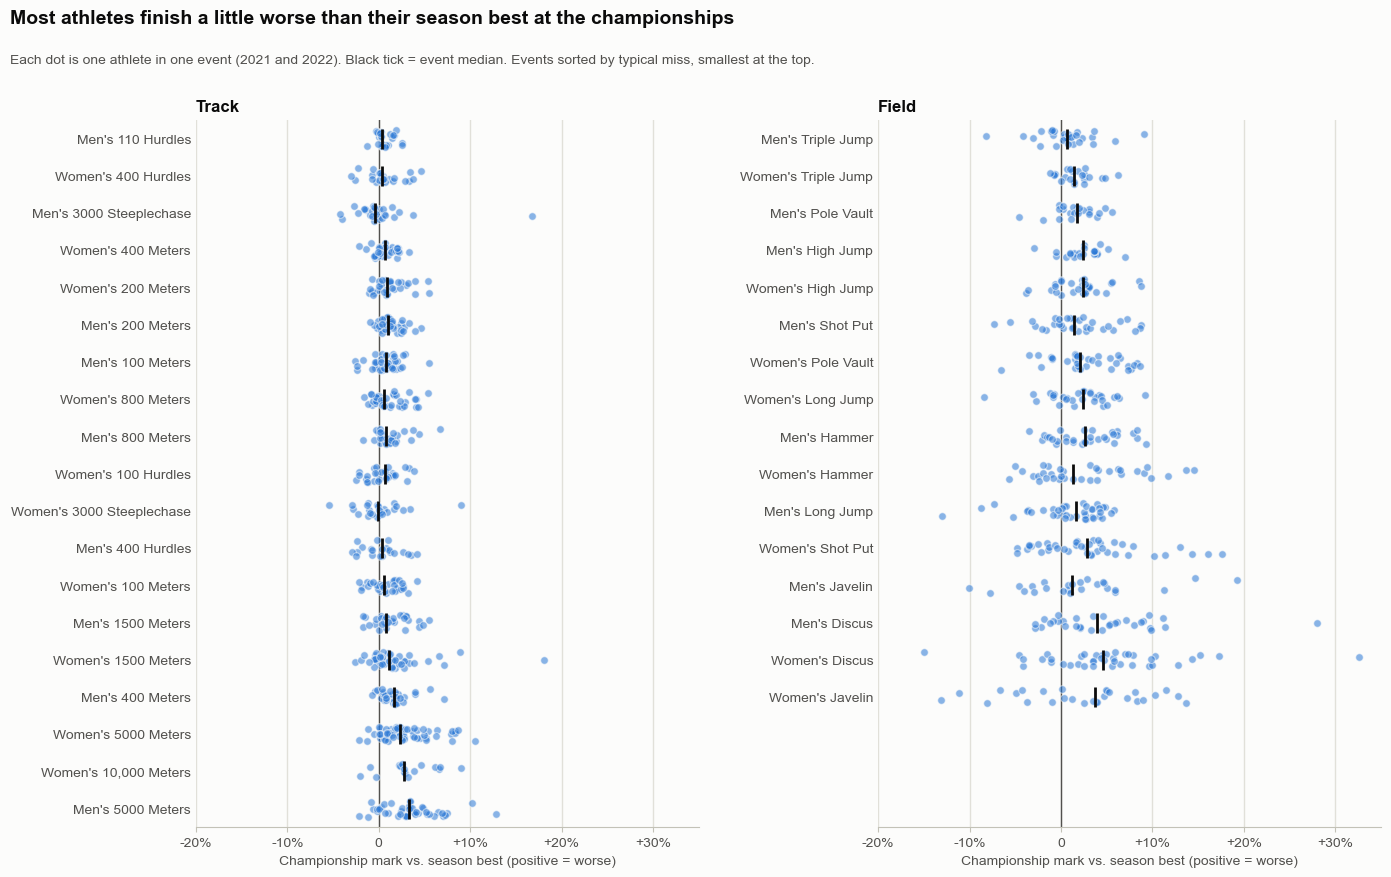

In [9]:
import matplotlib.pyplot as plt

INK, INK_2 = '#0b0b0b', '#52514e'
SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
DOT = '#2a78d6'

rng = np.random.default_rng(0)  # fixed jitter, so the plot is the same every run
panels = [('track', 'Track'), ('field', 'Field')]
max_rows = max(direct.loc[direct['event_type'] == t, 'event'].nunique() for t, _ in panels)
x_lo = np.floor(direct['pct_off_sb'].min() / 5) * 5
x_hi = np.ceil(direct['pct_off_sb'].max() / 5) * 5

style = {'font.family': ['Arial', 'DejaVu Sans'], 'font.size': 10,
         'axes.edgecolor': AXIS, 'xtick.color': AXIS, 'ytick.color': AXIS,
         'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2}
with plt.rc_context(style):
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.34 * max_rows + 2.4), facecolor=SURFACE)
    for ax, (event_type, title) in zip(axes, panels):
        df = direct[direct['event_type'] == event_type]
        order = per_event_direct.loc[event_type].sort_values('Typical miss (%)').index
        row = {event: i for i, event in enumerate(order)}
        y = df['event'].map(row) + rng.uniform(-0.22, 0.22, len(df))
        medians = df.groupby('event')['pct_off_sb'].median()

        ax.set_facecolor(SURFACE)
        ax.axvline(0, color=INK_2, linewidth=1, zorder=1)
        ax.scatter(df['pct_off_sb'], y, s=30, color=DOT, alpha=0.55,
                   edgecolors=SURFACE, linewidths=0.8, zorder=2)
        ax.scatter(medians.values, medians.index.map(row), marker='|', s=220,
                   color=INK, linewidths=2, zorder=3)

        ax.set_yticks(range(len(order)), order)
        ax.set_ylim(max_rows - 0.5, -0.5)
        ax.set_xlim(x_lo, x_hi)
        ax.xaxis.set_major_formatter(lambda v, _: f'{v:+.0f}%' if v else '0')
        ax.set_xlabel('Championship mark vs. season best (positive = worse)', color=INK_2)
        ax.grid(axis='x', color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        ax.tick_params(axis='y', length=0)
        for side in ('top', 'right', 'left'):
            ax.spines[side].set_visible(False)
        ax.set_title(title, loc='left', color=INK, fontsize=12, fontweight='bold')

    fig.text(0.01, 0.985, 'Most athletes finish a little worse than their season best at the championships',
             color=INK, fontsize=14, fontweight='bold', va='top')
    fig.text(0.01, 0.935, f'Each dot is one athlete in one event ({TRAIN_YEAR} and {TEST_YEAR}). '
             'Black tick = event median. Events sorted by typical miss, smallest at the top.',
             color=INK_2, fontsize=10, va='top')
    fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=3)
    plt.show()